<h2>IS453 Financial Analytics</h2><h2>Group Assignment - Home Improvement Loan Scorecard</h2>

### Step 2: Merged Data

This notebook follows `00_Customer_Segmentation.ipynb` and `01_flattened_Bureau_data.ipynb`. It merges the two outputs, runs a diagnostic EDA and engineers financially meaningful characteristics.

Scope: no imputation, outlier capping, feature removal, `TARGET`-based selection, WOE/IV, train/test split or modelling.

## 2.1 Business Context and Objectives

We are developing a credit scorecard for **Home Improvement Loans**. In Step 0 the customer population was defined with three eligibility criteria:

1. Owns residential property: `FLAG_OWN_REALTY = 'Y'`
2. Is at least 18 years old
3. Has positive reported income: `AMT_INCOME_TOTAL > 0`

These are **business assumptions** for selecting a plausible Home Improvement Loan population, not confirmed renovation-loan purposes.

In Step 1 the Bureau Data was flattened from many credit records per applicant to one applicant-level record.

This notebook combines both sources into one view of each applicant's:

- financial capacity (income, household size)
- employment stability
- existing debt obligations (bureau debt)
- repayment commitments (instalment on the requested loan)
- previous credit behaviour (delinquency, history length)
- housing and property characteristics

Raw attributes alone can mislead: a debt of 500,000 means something very different for an applicant earning 100,000 than for one earning 1,000,000. Feature engineering therefore turns raw amounts into **ratios and measures with a direct financial interpretation**, such as debt relative to income.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# show more columns and format floats for readability
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:,.4f}'.format)

## 2.2 Load and Validate Input Datasets

**Input file names.** The brief lists the inputs as `home_improvement_segement.csv` and `flattened_Bureau_Data.csv`. The files actually produced by Steps 0 and 1 are `home_improvement_segment.csv` and `01_flattened_Bureau_data.csv`, so those exact names are used below. If either file is missing the notebook stops with an error rather than substituting another file (for example, it does **not** fall back to `01_Bureau_Features_Full.csv`).

In [2]:
# input files produced by Step 0 and Step 1
application_path = 'data/home_improvement_segment.csv'
bureau_path = 'data/01_flattened_Bureau_data.csv'
dict_path = 'data/raw/IS453 Group Assignment - Data Dict.xlsx'

for path in [application_path, bureau_path, dict_path]:
    if not os.path.exists(path):
        raise FileNotFoundError(f'Required input file not found: {path}. Run the earlier step that creates it.')

application_df = pd.read_csv(application_path)
bureau_df = pd.read_csv(bureau_path)
app_dict = pd.read_excel(dict_path, sheet_name='Application Data')

# keep an untouched copy of the IDs and TARGET for later comparison
# (application_df itself is never modified, so it serves as the reference for all other columns)
target_orig = application_df[['SK_ID_CURR', 'TARGET']].copy()

print('Application data:', application_df.shape)
print('Bureau data:     ', bureau_df.shape)

Application data: (213312, 120)
Bureau data:      (181841, 24)


In [3]:
# key structure of both datasets
def id_summary(df):
    return [len(df), df.shape[1], df['SK_ID_CURR'].nunique(),
            df['SK_ID_CURR'].duplicated().sum(), df['SK_ID_CURR'].isnull().sum()]

id_table = pd.DataFrame({
    'Application Data': id_summary(application_df),
    'Bureau Data': id_summary(bureau_df),
}, index=['Number of rows', 'Number of columns', 'Unique SK_ID_CURR', 'Duplicate SK_ID_CURR', 'Missing SK_ID_CURR'])
id_table.index.name = 'Metric'
id_table.style.format('{:,.0f}')

,Application Data,Bureau Data
Metric,,
Number of rows,"213,312","181,841"
Number of columns,120,24
Unique SK_ID_CURR,"213,312","181,841"
Duplicate SK_ID_CURR,0,0
Missing SK_ID_CURR,0,0


In [4]:
# required checks before merging
overlap_cols = sorted((set(application_df.columns) & set(bureau_df.columns)) - {'SK_ID_CURR'})

checks = {
    '1. SK_ID_CURR in both datasets': 'SK_ID_CURR' in application_df.columns and 'SK_ID_CURR' in bureau_df.columns,
    '2. No missing applicant IDs': application_df['SK_ID_CURR'].notnull().all() and bureau_df['SK_ID_CURR'].notnull().all(),
    '3. SK_ID_CURR unique in both': application_df['SK_ID_CURR'].is_unique and bureau_df['SK_ID_CURR'].is_unique,
    '4. Compatible ID data types': application_df['SK_ID_CURR'].dtype == bureau_df['SK_ID_CURR'].dtype,
    '5. No overlapping non-key columns': len(overlap_cols) == 0,
    '6. TARGET in Application Data': 'TARGET' in application_df.columns,
    '7. TARGET not in Bureau Data': 'TARGET' not in bureau_df.columns,
    '8. No duplicate column names': application_df.columns.is_unique and bureau_df.columns.is_unique,
}
for name, result in checks.items():
    print(f'{name}: {result}')
print('\nID data types:', application_df['SK_ID_CURR'].dtype, '/', bureau_df['SK_ID_CURR'].dtype)
print('Overlapping non-key columns:', overlap_cols if overlap_cols else 'none')
print('Bureau IDs not in the application segment:', (~bureau_df['SK_ID_CURR'].isin(application_df['SK_ID_CURR'])).sum())

# stop if the one-row-per-applicant structure is violated
if not all(checks.values()):
    raise ValueError('Input validation failed - see the checks above. Duplicates are not dropped automatically.')

1. SK_ID_CURR in both datasets: True
2. No missing applicant IDs: True
3. SK_ID_CURR unique in both: True
4. Compatible ID data types: True
5. No overlapping non-key columns: True
6. TARGET in Application Data: True
7. TARGET not in Bureau Data: True
8. No duplicate column names: True

ID data types: int64 / int64
Overlapping non-key columns: none
Bureau IDs not in the application segment: 0


Both inputs have exactly one row per `SK_ID_CURR`, no missing IDs, matching integer ID types and no overlapping column names, so the merge cannot overwrite or duplicate anything. `TARGET` exists only in the application data. It is carried through unchanged and **is not used** in any feature calculation below.

## 2.3 Merge Application and Bureau Data

**Why a LEFT JOIN?**

- The application data defines our **target population**: every eligible homeowner must stay in the dataset.
- Not every applicant has historical bureau records.
- A LEFT JOIN keeps all eligible applicants; bureau columns are simply empty for those without history.
- An INNER JOIN would drop applicants without bureau history. They are often thin-file customers whose risk may differ, so dropping them would introduce **sample-selection bias**, and the scorecard could not score them in production.
- `SK_ID_CURR` is unique in both sources, and `validate='one_to_one'` makes pandas raise an error if that is ever not true, so rows cannot multiply.

In [5]:
# LEFT JOIN on SK_ID_CURR
merged_df = application_df.merge(
    bureau_df,
    on='SK_ID_CURR',
    how='left',
    validate='one_to_one',
    indicator=True
)

merged_df['_merge'].value_counts()

C:\Users\rae ng\AppData\Local\Temp\ipykernel_32452\2634438796.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df = application_df.merge(
C:\Users\rae ng\AppData\Local\Temp\ipykernel_32452\2634438796.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df = application_df.merge(


_merge
both          181841
left_only      31471
right_only         0
Name: count, dtype: int64

In [6]:
# merge validation summary
matched = (merged_df['_merge'] == 'both').sum()

merge_summary = pd.DataFrame({'Result': [
    f'{len(application_df):,}',
    f'{len(bureau_df):,}',
    f'{matched:,}',
    f'{(merged_df["_merge"] == "left_only").sum():,}',
    f'{matched / application_df["SK_ID_CURR"].nunique() * 100:.2f}%',
    f'{len(merged_df):,}',
]}, index=['Application applicants before merge', 'Flattened bureau applicants', 'Successfully matched applicants',
           'Applicants without bureau records', 'Bureau coverage (%)', 'Final merged rows'])
merge_summary.index.name = 'Metric'
merge_summary

,Result
Metric,
Application applicants before merge,"213,312"
Flattened bureau applicants,"181,841"
Successfully matched applicants,"181,841"
Applicants without bureau records,"31,471"
Bureau coverage (%),85.25%
Final merged rows,"213,312"


## 2.4 Application-Specific Feature Engineering

Each feature below has a clear financial meaning. All ratios use a **safe division** rule: if the numerator or denominator is missing, or the denominator is zero/negative where that is economically invalid, the result is `NaN`. No rows are dropped and no constants are substituted.

**Units check from the data dictionary**

The dictionary defines `AMT_INCOME_TOTAL` as *"Income of the client"* and `AMT_ANNUITY` as *"Loan annuity"*, but **does not state the period** of either. We test the brief's monthly assumption below before using it.

In [7]:
# dictionary definitions of the inputs used
used_inputs = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
               'CNT_FAM_MEMBERS', 'YEARS_BUILD_AVG', 'YEARS_BEGINEXPLUATATION_AVG']
with pd.option_context('display.max_colwidth', 200):
    display(app_dict[app_dict.iloc[:, 0].isin(used_inputs)].set_index(app_dict.columns[0]))

,Description,Special
Row,,
AMT_INCOME_TOTAL,Income of the client,NaN
AMT_CREDIT,Credit amount of the loan,NaN
AMT_ANNUITY,Loan annuity,NaN
AMT_GOODS_PRICE,For consumer loans it is the price of the goods for which the loan is given,NaN
DAYS_BIRTH,Client's age in days at the time of application,time only relative to the application
DAYS_EMPLOYED,How many days before the application the person started current employment,time only relative to the application
CNT_FAM_MEMBERS,How many family members does client have,NaN
YEARS_BEGINEXPLUATATION_AVG,"Normalized information about building where the client lives, What is average (_AVG suffix), modus (_MODE suffix), median (_MEDI suffix) apartment size, common area, living area, age of building, ...",normalized
YEARS_BUILD_AVG,"Normalized information about building where the client lives, What is average (_AVG suffix), modus (_MODE suffix), median (_MEDI suffix) apartment size, common area, living area, age of building, ...",normalized


In [8]:
# safe division: NaN when inputs are missing or the denominator is zero/negative
def safe_divide(numerator, denominator):
    valid = numerator.notnull() & denominator.notnull() & (denominator > 0)
    return (numerator / denominator).where(valid)

new_app_features = []

### 1. Applicant Age

`AGE_YEARS = -DAYS_BIRTH / 365.25`, the applicant's age at application.

In [9]:
merged_df['AGE_YEARS'] = -merged_df['DAYS_BIRTH'] / 365.25
new_app_features.append('AGE_YEARS')
merged_df['AGE_YEARS'].describe()

C:\Users\rae ng\AppData\Local\Temp\ipykernel_32452\777114531.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df['AGE_YEARS'] = -merged_df['DAYS_BIRTH'] / 365.25


count   213,312.0000
mean         44.8529
std          11.9128
min          20.5038
25%          35.1896
50%          44.5366
75%          54.7844
max          69.0732
Name: AGE_YEARS, dtype: float64

### 2. Employment Tenure

`EMPLOYMENT_YEARS = -DAYS_EMPLOYED / 365.25`, with the special code 365243 treated as missing (not employed), and a flag recording the special code so that this information is not lost.

In [10]:
# special code -> flag, tenure set to missing for those applicants
special_emp = merged_df['DAYS_EMPLOYED'] == 365243
merged_df['FLAG_DAYS_EMPLOYED_SPECIAL'] = special_emp.astype(int)
merged_df['EMPLOYMENT_YEARS'] = (-merged_df['DAYS_EMPLOYED'] / 365.25).where(~special_emp)
new_app_features += ['FLAG_DAYS_EMPLOYED_SPECIAL', 'EMPLOYMENT_YEARS']

print(f'Special code applicants: {special_emp.sum():,}')
merged_df['EMPLOYMENT_YEARS'].describe()

Special code applicants: 42,230


C:\Users\rae ng\AppData\Local\Temp\ipykernel_32452\2589237417.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df['FLAG_DAYS_EMPLOYED_SPECIAL'] = special_emp.astype(int)
C:\Users\rae ng\AppData\Local\Temp\ipykernel_32452\2589237417.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df['EMPLOYMENT_YEARS'] = (-merged_df['DAYS_EMPLOYED'] / 365.25).where(~special_emp)


count   171,082.0000
mean          6.6626
std           6.5433
min           0.0000
25%           2.1355
50%           4.5640
75%           8.8816
max          49.0404
Name: EMPLOYMENT_YEARS, dtype: float64

### 3–6. Affordability and household ratios

| Feature | Formula | Interpretation |
|---|---|---|
| `LOAN_TO_INCOME` | `AMT_CREDIT / AMT_INCOME_TOTAL` | Requested borrowing relative to reported income|
| `ANNUITY_TO_INCOME` | `AMT_ANNUITY / AMT_INCOME_TOTAL` | Instalment burden relative to income |
| `CREDIT_TO_GOODS_RATIO` | `AMT_CREDIT / AMT_GOODS_PRICE` | Financing relative to the price of the goods |
| `INCOME_PER_FAMILY_MEMBER` | `AMT_INCOME_TOTAL / CNT_FAM_MEMBERS` | Income per household member |

In [11]:
merged_df['LOAN_TO_INCOME'] = safe_divide(merged_df['AMT_CREDIT'], merged_df['AMT_INCOME_TOTAL'])
merged_df['ANNUITY_TO_INCOME'] = safe_divide(merged_df['AMT_ANNUITY'], merged_df['AMT_INCOME_TOTAL'])
merged_df['CREDIT_TO_GOODS_RATIO'] = safe_divide(merged_df['AMT_CREDIT'], merged_df['AMT_GOODS_PRICE'])
merged_df['INCOME_PER_FAMILY_MEMBER'] = safe_divide(merged_df['AMT_INCOME_TOTAL'], merged_df['CNT_FAM_MEMBERS'])
new_app_features += ['LOAN_TO_INCOME', 'ANNUITY_TO_INCOME', 'CREDIT_TO_GOODS_RATIO', 'INCOME_PER_FAMILY_MEMBER']

# goods price coverage by contract type
print('AMT_GOODS_PRICE missing by contract type:')
print(merged_df.groupby('NAME_CONTRACT_TYPE')['AMT_GOODS_PRICE'].apply(lambda s: s.isnull().sum()).to_string())

merged_df[['LOAN_TO_INCOME', 'ANNUITY_TO_INCOME', 'CREDIT_TO_GOODS_RATIO', 'INCOME_PER_FAMILY_MEMBER']].describe().T

C:\Users\rae ng\AppData\Local\Temp\ipykernel_32452\860705578.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df['LOAN_TO_INCOME'] = safe_divide(merged_df['AMT_CREDIT'], merged_df['AMT_INCOME_TOTAL'])
C:\Users\rae ng\AppData\Local\Temp\ipykernel_32452\860705578.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df['ANNUITY_TO_INCOME'] = safe_divide(merged_df['AMT_ANNUITY'], merged_df['AMT_INCOME_TOTAL'])
C:\Users\rae ng\AppData\Local\Temp\ipykernel_32452\860705578.py:3: PerformanceWarning: DataFrame is highly f

AMT_GOODS_PRICE missing by contract type:
NAME_CONTRACT_TYPE
Cash loans           0
Revolving loans    223


,count,mean,std,min,25%,50%,75%,max
LOAN_TO_INCOME,"213,312.0000",3.8703,2.6414,0.0048,2.0000,3.1600,5.0333,84.7368
ANNUITY_TO_INCOME,"213,309.0000",0.1797,0.0939,0.0002,0.1138,0.1618,0.2272,1.8760
CREDIT_TO_GOODS_RATIO,"213,089.0000",1.1255,0.1245,0.1500,1.0000,1.1188,1.1980,6.0000
INCOME_PER_FAMILY_MEMBER,"213,310.0000","92,998.4444","110,823.2782","4,875.0000","48,000.0000","75,000.0000","112,500.0000","39,000,000.0000"


`AMT_GOODS_PRICE` is available for all cash loans and missing only for some revolving loans, so `CREDIT_TO_GOODS_RATIO` is well populated. The missing values stay missing.

## 2.5 Cross-Dataset Feature Engineering

These features combine application and bureau information and cannot be built from either source alone. First, check which bureau inputs actually exist in the flattened file.

In [12]:
# check the real bureau column names before using them
bureau_cols = [c for c in bureau_df.columns if c != 'SK_ID_CURR']

required_inputs = {
    'BUREAU_DEBT_TO_INCOME': ['TOTAL_ACTIVE_DEBT', 'AMT_INCOME_TOTAL'],
    'TOTAL_EXPOSURE_TO_INCOME': ['TOTAL_ACTIVE_DEBT', 'AMT_CREDIT', 'AMT_INCOME_TOTAL'],
    'BUREAU_ANNUITY_TO_INCOME': ['TOTAL_ACTIVE_ANNUITY', 'AMT_INCOME_TOTAL'],
    'COMBINED_ANNUITY_TO_INCOME': ['TOTAL_ACTIVE_ANNUITY', 'AMT_ANNUITY', 'AMT_INCOME_TOTAL'],
    'AVG_DEBT_PER_ACTIVE_LOAN': ['TOTAL_ACTIVE_DEBT', 'ACTIVE_LOAN_COUNT'],
    'CREDIT_HISTORY_AGE_RATIO': ['OLDEST_CREDIT_AGE', 'AGE_YEARS'],
    'ACTIVE_LOANS_PER_INCOME': ['ACTIVE_LOAN_COUNT', 'AMT_INCOME_TOTAL'],
    'EXISTING_DEBT_SHARE_OF_EXPOSURE': ['TOTAL_ACTIVE_DEBT', 'AMT_CREDIT'],
}

print('Flattened bureau columns:', bureau_cols, '\n')
availability = pd.DataFrame({
    'Required inputs': [', '.join(v) for v in required_inputs.values()],
    'Missing inputs': [', '.join(c for c in v if c not in merged_df.columns) or '-' for v in required_inputs.values()],
}, index=list(required_inputs))
availability['Can be created'] = availability['Missing inputs'] == '-'
availability.index.name = 'Feature'
availability

Flattened bureau columns: ['BUREAU_LOAN_COUNT', 'ACTIVE_LOAN_COUNT', 'ADVERSE_STATUS_COUNT', 'ACTIVE_LOAN_RATIO', 'CREDIT_TYPE_DIVERSITY', 'TOTAL_ACTIVE_DEBT', 'DEBT_TO_CREDIT_RATIO', 'TOTAL_REVOLVING_LIMIT', 'MAX_DAYS_OVERDUE', 'OVERDUE_LOAN_COUNT', 'TOTAL_OVERDUE_AMOUNT', 'MAX_HIST_OVERDUE', 'TOTAL_PROLONGATIONS', 'OLDEST_CREDIT_AGE', 'MOST_RECENT_CREDIT_AGE', 'MAX_REMAINING_DURATION', 'LAST_CREDIT_END_AGE', 'LATEST_BUREAU_UPDATE_AGE', 'ACTIVE_CONSUMER_CREDIT_COUNT', 'ACTIVE_CREDIT_CARD_COUNT', 'MORTGAGE_COUNT', 'CAR_LOAN_COUNT', 'MICROLOAN_COUNT'] 



,Required inputs,Missing inputs,Can be created
Feature,,,
BUREAU_DEBT_TO_INCOME,"TOTAL_ACTIVE_DEBT, AMT_INCOME_TOTAL",-,True
TOTAL_EXPOSURE_TO_INCOME,"TOTAL_ACTIVE_DEBT, AMT_CREDIT, AMT_INCOME_TOTAL",-,True
BUREAU_ANNUITY_TO_INCOME,"TOTAL_ACTIVE_ANNUITY, AMT_INCOME_TOTAL",TOTAL_ACTIVE_ANNUITY,False
COMBINED_ANNUITY_TO_INCOME,"TOTAL_ACTIVE_ANNUITY, AMT_ANNUITY, AMT_INCOME_...",TOTAL_ACTIVE_ANNUITY,False
AVG_DEBT_PER_ACTIVE_LOAN,"TOTAL_ACTIVE_DEBT, ACTIVE_LOAN_COUNT",-,True
CREDIT_HISTORY_AGE_RATIO,"OLDEST_CREDIT_AGE, AGE_YEARS",-,True
ACTIVE_LOANS_PER_INCOME,"ACTIVE_LOAN_COUNT, AMT_INCOME_TOTAL",-,True
EXISTING_DEBT_SHARE_OF_EXPOSURE,"TOTAL_ACTIVE_DEBT, AMT_CREDIT",-,True


`TOTAL_ACTIVE_ANNUITY` is **not** in the flattened bureau file. Step 1 dropped it because bureau annuities were unreported for about 59% of applicants. Therefore **`BUREAU_ANNUITY_TO_INCOME` and `COMBINED_ANNUITY_TO_INCOME` cannot be created**. We do not substitute another variable or reload the full feature file, because a repayment-burden measure built on mostly missing annuities would be misleading.

**Double-counting check.** `TOTAL_EXPOSURE_TO_INCOME` adds existing bureau debt to the requested loan. If the bureau already contained the current loan, it would be counted twice. The bureau records credits from other institutions reported *before* the application. A credit opened on the application day would have `MOST_RECENT_CREDIT_AGE = 0`:

In [13]:
# applicants with a bureau credit opened on the application day
merged_df['HAS_BUREAU_HISTORY'] = (merged_df['_merge'] == 'both').astype(int)
same_day = (merged_df['MOST_RECENT_CREDIT_AGE'] == 0).sum()
print(f'Applicants with a bureau credit opened on the application day: {same_day} ({same_day / merged_df["HAS_BUREAU_HISTORY"].sum():.4%} of matched)')

Applicants with a bureau credit opened on the application day: 4 (0.0022% of matched)


C:\Users\rae ng\AppData\Local\Temp\ipykernel_32452\2271485235.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df['HAS_BUREAU_HISTORY'] = (merged_df['_merge'] == 'both').astype(int)


Only a handful of applicants have any bureau credit opened on the application day, so double counting of the current loan is negligible.

**Features created**

| Feature | Formula | Interpretation |
|---|---|---|
| `BUREAU_DEBT_TO_INCOME` | `TOTAL_ACTIVE_DEBT / AMT_INCOME_TOTAL` | Existing outstanding debt relative to income. Two borrowers with the same debt can have very different capacity. |
| `TOTAL_EXPOSURE_TO_INCOME` | `(TOTAL_ACTIVE_DEBT + AMT_CREDIT) / AMT_INCOME_TOTAL` | Existing debt plus the requested loan relative to income. A **balance-to-income** measure, not a repayment ratio. |
| `AVG_DEBT_PER_ACTIVE_LOAN` | `TOTAL_ACTIVE_DEBT / ACTIVE_LOAN_COUNT` | Typical size of each current obligation. Missing when there are no active loans. |
| `CREDIT_HISTORY_AGE_RATIO` | `OLDEST_CREDIT_AGE / AGE_YEARS` | Observable credit history relative to age. |
| `ACTIVE_LOANS_PER_INCOME` | `ACTIVE_LOAN_COUNT / (AMT_INCOME_TOTAL / 100,000)` | Number of current obligations per 100,000 of income (exploratory). |
| `EXISTING_DEBT_SHARE_OF_EXPOSURE` | `TOTAL_ACTIVE_DEBT / (TOTAL_ACTIVE_DEBT + AMT_CREDIT)` | Share of total post-loan exposure that is existing debt: how much the new loan adds to an already-indebted applicant (additional feature). |

All are missing for applicants without bureau history and whenever a bureau input is missing. They are never set to zero.

In [14]:
# cross-dataset features (only those whose inputs exist)
new_cross_features = []
total_exposure = merged_df['TOTAL_ACTIVE_DEBT'] + merged_df['AMT_CREDIT']

if availability.loc['BUREAU_DEBT_TO_INCOME', 'Can be created']:
    merged_df['BUREAU_DEBT_TO_INCOME'] = safe_divide(merged_df['TOTAL_ACTIVE_DEBT'], merged_df['AMT_INCOME_TOTAL'])
    new_cross_features.append('BUREAU_DEBT_TO_INCOME')

if availability.loc['TOTAL_EXPOSURE_TO_INCOME', 'Can be created']:
    merged_df['TOTAL_EXPOSURE_TO_INCOME'] = safe_divide(total_exposure, merged_df['AMT_INCOME_TOTAL'])
    new_cross_features.append('TOTAL_EXPOSURE_TO_INCOME')

if availability.loc['AVG_DEBT_PER_ACTIVE_LOAN', 'Can be created']:
    merged_df['AVG_DEBT_PER_ACTIVE_LOAN'] = safe_divide(merged_df['TOTAL_ACTIVE_DEBT'], merged_df['ACTIVE_LOAN_COUNT'])
    new_cross_features.append('AVG_DEBT_PER_ACTIVE_LOAN')

if availability.loc['CREDIT_HISTORY_AGE_RATIO', 'Can be created']:
    merged_df['CREDIT_HISTORY_AGE_RATIO'] = safe_divide(merged_df['OLDEST_CREDIT_AGE'], merged_df['AGE_YEARS'])
    new_cross_features.append('CREDIT_HISTORY_AGE_RATIO')

if availability.loc['ACTIVE_LOANS_PER_INCOME', 'Can be created']:
    merged_df['ACTIVE_LOANS_PER_INCOME'] = safe_divide(merged_df['ACTIVE_LOAN_COUNT'], merged_df['AMT_INCOME_TOTAL'] / 100000)
    new_cross_features.append('ACTIVE_LOANS_PER_INCOME')

if availability.loc['EXISTING_DEBT_SHARE_OF_EXPOSURE', 'Can be created']:
    merged_df['EXISTING_DEBT_SHARE_OF_EXPOSURE'] = safe_divide(merged_df['TOTAL_ACTIVE_DEBT'], total_exposure)
    new_cross_features.append('EXISTING_DEBT_SHARE_OF_EXPOSURE')

not_created = availability.index[~availability['Can be created']].tolist()
print('Created:', new_cross_features)
print('Not created (missing inputs):', not_created)

merged_df[new_cross_features].describe().T

Created: ['BUREAU_DEBT_TO_INCOME', 'TOTAL_EXPOSURE_TO_INCOME', 'AVG_DEBT_PER_ACTIVE_LOAN', 'CREDIT_HISTORY_AGE_RATIO', 'ACTIVE_LOANS_PER_INCOME', 'EXISTING_DEBT_SHARE_OF_EXPOSURE']
Not created (missing inputs): ['BUREAU_ANNUITY_TO_INCOME', 'COMBINED_ANNUITY_TO_INCOME']


C:\Users\rae ng\AppData\Local\Temp\ipykernel_32452\2670860557.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df['BUREAU_DEBT_TO_INCOME'] = safe_divide(merged_df['TOTAL_ACTIVE_DEBT'], merged_df['AMT_INCOME_TOTAL'])
C:\Users\rae ng\AppData\Local\Temp\ipykernel_32452\2670860557.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df['TOTAL_EXPOSURE_TO_INCOME'] = safe_divide(total_exposure, merged_df['AMT_INCOME_TOTAL'])
C:\Users\rae ng\AppData\Local\Temp\ipykernel_32452\2670860557.py:14: PerformanceWarning: DataF

,count,mean,std,min,25%,50%,75%,max
BUREAU_DEBT_TO_INCOME,"174,539.0000",3.6894,7.5371,0.0000,0.0000,1.2618,4.3407,388.0000
TOTAL_EXPOSURE_TO_INCOME,"174,539.0000",7.5349,7.9757,0.0091,3.2728,5.5786,9.0912,394.0000
AVG_DEBT_PER_ACTIVE_LOAN,"142,239.0000","353,436.4444","866,554.7686",0.0000,"42,526.6650","134,043.7500","329,646.1837","43,650,000.0000"
CREDIT_HISTORY_AGE_RATIO,"181,841.0000",0.1116,0.0583,0.0000,0.0663,0.1129,0.1502,0.3066
ACTIVE_LOANS_PER_INCOME,"181,841.0000",1.4183,1.4382,0.0000,0.4938,1.1111,1.9048,26.6667
EXISTING_DEBT_SHARE_OF_EXPOSURE,"174,539.0000",0.3278,0.3054,0.0000,0.0000,0.2722,0.5863,0.9954


In [15]:
# credit history ratio: check the bureau observation window
print(f"Maximum OLDEST_CREDIT_AGE in bureau data: {merged_df['OLDEST_CREDIT_AGE'].max():.2f} years")
print(f"Applicants whose oldest credit would have started before age 18: "
      f"{((merged_df['AGE_YEARS'] - merged_df['OLDEST_CREDIT_AGE']) < 18).sum()}")

Maximum OLDEST_CREDIT_AGE in bureau data: 8.00 years
Applicants whose oldest credit would have started before age 18: 13


`CREDIT_HISTORY_AGE_RATIO` must be read with care: the bureau only shows credits opened within about the **last 8 years**, so `OLDEST_CREDIT_AGE` is capped there. For older applicants the ratio understates true history; it is most informative for younger applicants. A few applicants appear to have started credit before 18, which is likely a data-quality issue to review later.

## 2.6 Validate Newly Engineered Characteristics

In [16]:
# quality review for every new characteristic
formulas = {
    'AGE_YEARS': '-DAYS_BIRTH / 365.25',
    'FLAG_DAYS_EMPLOYED_SPECIAL': 'DAYS_EMPLOYED == 365243',
    'EMPLOYMENT_YEARS': '-DAYS_EMPLOYED / 365.25 (special code -> NaN)',
    'LOAN_TO_INCOME': 'AMT_CREDIT / AMT_INCOME_TOTAL',
    'ANNUITY_TO_INCOME': 'AMT_ANNUITY / AMT_INCOME_TOTAL (same period)',
    'CREDIT_TO_GOODS_RATIO': 'AMT_CREDIT / AMT_GOODS_PRICE',
    'INCOME_PER_FAMILY_MEMBER': 'AMT_INCOME_TOTAL / CNT_FAM_MEMBERS',
    'EMPLOYMENT_AGE_RATIO': 'EMPLOYMENT_YEARS / AGE_YEARS',
    'BUREAU_DEBT_TO_INCOME': 'TOTAL_ACTIVE_DEBT / AMT_INCOME_TOTAL',
    'TOTAL_EXPOSURE_TO_INCOME': '(TOTAL_ACTIVE_DEBT + AMT_CREDIT) / AMT_INCOME_TOTAL',
    'AVG_DEBT_PER_ACTIVE_LOAN': 'TOTAL_ACTIVE_DEBT / ACTIVE_LOAN_COUNT',
    'CREDIT_HISTORY_AGE_RATIO': 'OLDEST_CREDIT_AGE / AGE_YEARS',
    'ACTIVE_LOANS_PER_INCOME': 'ACTIVE_LOAN_COUNT / (AMT_INCOME_TOTAL / 100,000)',
    'EXISTING_DEBT_SHARE_OF_EXPOSURE': 'TOTAL_ACTIVE_DEBT / (TOTAL_ACTIVE_DEBT + AMT_CREDIT)',
}
new_features = new_app_features + new_cross_features

validation = pd.DataFrame({
    'Formula / source': [formulas[c] for c in new_features],
    'Non-missing count': [merged_df[c].notnull().sum() for c in new_features],
    'Missing %': [merged_df[c].isnull().mean() * 100 for c in new_features],
    'Minimum': [merged_df[c].min() for c in new_features],
    'Median': [merged_df[c].median() for c in new_features],
    'Maximum': [merged_df[c].max() for c in new_features],
    '99th percentile': [merged_df[c].quantile(0.99) for c in new_features],
    'Negative count': [(merged_df[c] < 0).sum() for c in new_features],
    'Infinite count': [np.isinf(merged_df[c]).sum() for c in new_features],
    'Distinct values': [merged_df[c].nunique() for c in new_features],
}, index=new_features)
validation.index.name = 'Characteristic'

with pd.option_context('display.max_colwidth', None):
    display(validation.style.format({'Non-missing count': '{:,.0f}', 'Missing %': '{:.2f}', 'Minimum': '{:,.3f}', 'Median': '{:,.3f}',
                                     'Maximum': '{:,.3f}', '99th percentile': '{:,.3f}', 'Negative count': '{:,.0f}',
                                     'Infinite count': '{:,.0f}', 'Distinct values': '{:,.0f}'}))

,Formula / source,Non-missing count,Missing %,Minimum,Median,Maximum,99th percentile,Negative count,Infinite count,Distinct values
Characteristic,,,,,,,,,,
AGE_YEARS,-DAYS_BIRTH / 365.25,"213,312",0.00,20.504,44.537,69.073,67.039,0,0,"17,392"
FLAG_DAYS_EMPLOYED_SPECIAL,DAYS_EMPLOYED == 365243,"213,312",0.00,0.000,0.000,1.000,1.000,0,0,2
EMPLOYMENT_YEARS,-DAYS_EMPLOYED / 365.25 (special code -> NaN),"171,082",19.80,0.000,4.564,49.040,31.485,0,0,"11,843"
LOAN_TO_INCOME,AMT_CREDIT / AMT_INCOME_TOTAL,"213,312",0.00,0.005,3.160,84.737,12.729,0,0,"39,925"
ANNUITY_TO_INCOME,AMT_ANNUITY / AMT_INCOME_TOTAL (same period),"213,309",0.00,0.000,0.162,1.876,0.478,0,0,"70,672"
CREDIT_TO_GOODS_RATIO,AMT_CREDIT / AMT_GOODS_PRICE,"213,089",0.10,0.150,1.119,6.000,1.475,0,0,"2,761"
INCOME_PER_FAMILY_MEMBER,AMT_INCOME_TOTAL / CNT_FAM_MEMBERS,"213,310",0.00,"4,875.000","75,000.000","39,000,000.000","337,500.000",0,0,"2,072"
BUREAU_DEBT_TO_INCOME,TOTAL_ACTIVE_DEBT / AMT_INCOME_TOTAL,"174,539",18.18,0.000,1.262,388.000,36.049,0,0,"121,600"
TOTAL_EXPOSURE_TO_INCOME,(TOTAL_ACTIVE_DEBT + AMT_CREDIT) / AMT_INCOME_TOTAL,"174,539",18.18,0.009,5.579,394.000,40.151,0,0,"138,610"


In [17]:
# further checks
app_cols = application_df.columns.tolist()


print('Exact duplicate engineered columns:', merged_df[new_features].T.duplicated().sum())
print('Engineered columns duplicating an existing column:',
      [c for c in new_features if any(merged_df[c].equals(merged_df[o]) for o in app_cols + bureau_cols)])

# missing values propagated from inputs (bureau-based features vs no bureau history)
print('\nCross features missing for applicants WITHOUT bureau history (should be 100%):')
print((merged_df.loc[merged_df['HAS_BUREAU_HISTORY'] == 0, new_cross_features].isnull().mean() * 100).round(2).to_string())
print('\nCross features missing for applicants WITH bureau history:')
print((merged_df.loc[merged_df['HAS_BUREAU_HISTORY'] == 1, new_cross_features].isnull().mean() * 100).round(2).to_string())

# very little variation
print('\nShare of the most common value per new feature (> 95% would be near-constant):')
print((merged_df[new_features].apply(lambda s: s.value_counts(normalize=True).iloc[0]) * 100).round(2).sort_values(ascending=False).head(5).to_string())

Exact duplicate engineered columns: 0
Engineered columns duplicating an existing column: []

Cross features missing for applicants WITHOUT bureau history (should be 100%):
BUREAU_DEBT_TO_INCOME             100.0000
TOTAL_EXPOSURE_TO_INCOME          100.0000
AVG_DEBT_PER_ACTIVE_LOAN          100.0000
CREDIT_HISTORY_AGE_RATIO          100.0000
ACTIVE_LOANS_PER_INCOME           100.0000
EXISTING_DEBT_SHARE_OF_EXPOSURE   100.0000

Cross features missing for applicants WITH bureau history:
BUREAU_DEBT_TO_INCOME              4.0200
TOTAL_EXPOSURE_TO_INCOME           4.0200
AVG_DEBT_PER_ACTIVE_LOAN          21.7800
CREDIT_HISTORY_AGE_RATIO           0.0000
ACTIVE_LOANS_PER_INCOME            0.0000
EXISTING_DEBT_SHARE_OF_EXPOSURE    4.0200

Share of the most common value per new feature (> 95% would be near-constant):
FLAG_DAYS_EMPLOYED_SPECIAL        80.2000
CREDIT_TO_GOODS_RATIO             34.0900
BUREAU_DEBT_TO_INCOME             27.4400
EXISTING_DEBT_SHARE_OF_EXPOSURE   27.4400
ACTIVE_LOA

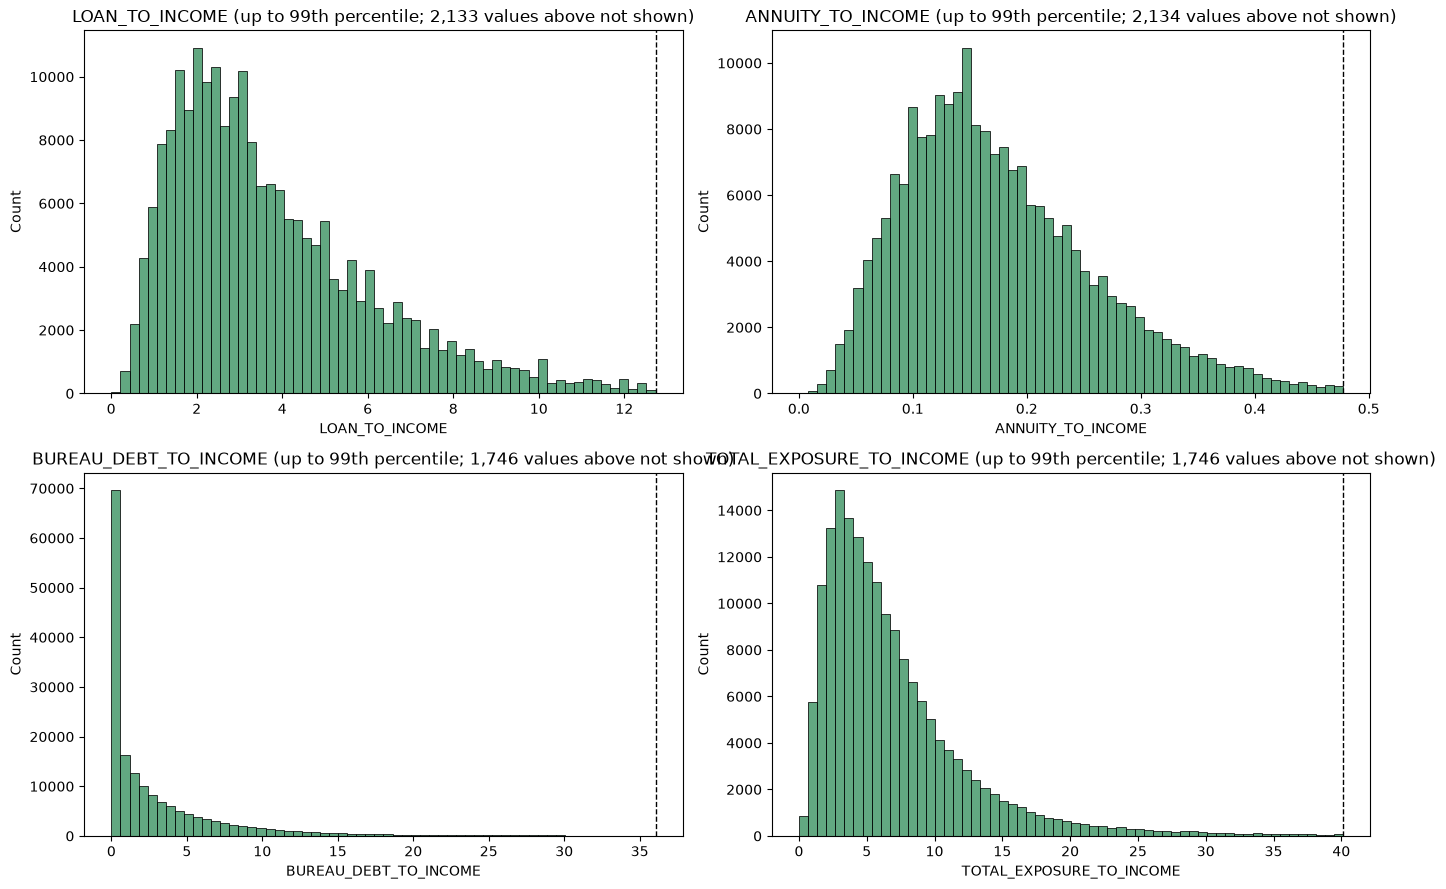

In [18]:
# distributions of selected new ratios (99th percentile shown as a dashed line)
ratio_plots = ['LOAN_TO_INCOME', 'ANNUITY_TO_INCOME', 'BUREAU_DEBT_TO_INCOME', 'TOTAL_EXPOSURE_TO_INCOME']

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for var, axis in zip(ratio_plots, axes.flatten()):
    values = merged_df[var].dropna()
    p99 = values.quantile(0.99)
    sns.histplot(values[values <= p99], bins=60, ax=axis, color='seagreen')
    axis.axvline(p99, color='black', linestyle='--', linewidth=1)
    axis.set_title(f'{var} (up to 99th percentile; {(values > p99).sum():,} values above not shown)')
plt.tight_layout()
plt.show()

**Validation findings**

- **No infinite values and no negative values** in any new characteristic. Safe division converted zero denominators to `NaN`.
- **Large ratios:** the income-based ratios (`LOAN_TO_INCOME`, `BUREAU_DEBT_TO_INCOME`, `TOTAL_EXPOSURE_TO_INCOME`) have maxima far above their 99th percentiles, driven by very large bureau debts or very low incomes. They are **kept unchanged**; coarse classing will group the tail.
- **Missing values propagate as intended:** cross-dataset features are 100% missing for applicants without bureau history, and partly missing for matched applicants where the bureau input is missing or not applicable (e.g. `AVG_DEBT_PER_ACTIVE_LOAN` when there are no active loans). `EMPLOYMENT_YEARS` and `EMPLOYMENT_AGE_RATIO` are missing exactly for the special-code applicants.
- **Little variation:** `FLAG_DAYS_EMPLOYED_SPECIAL` is binary by design; no continuous feature is near-constant.
- **No exact duplicates** of each other or of existing columns. Some new features will correlate with their inputs (e.g. `TOTAL_EXPOSURE_TO_INCOME` with `LOAN_TO_INCOME`). That redundancy is assessed in the next stage, not here.
- **Units:** income-based ratios are on a same-period basis because the income/annuity periods are not stated in the dictionary; they should be presented as relative indices.

## 2.7 Feature Engineering Documentation

The feature dictionary is generated from the columns actually present, so it only lists features that were created. The imported Step 1 bureau features are listed separately.

In [19]:
# documentation for each newly created characteristic
feature_docs = {
    'AGE_YEARS': ('Application', 'Age at application in years.', 'Complete; all applicants are 18+.'),
    'FLAG_DAYS_EMPLOYED_SPECIAL': ('Application', 'Not currently employed (pensioner/unemployed special code).', 'Records the 365243 code so it is not lost when tenure is set to missing.'),
    'EMPLOYMENT_YEARS': ('Application', 'Years in current employment; job stability.', 'Missing for special-code applicants (not employed).'),
    'LOAN_TO_INCOME': ('Application', 'Size of requested loan relative to income.', 'Income period not stated in dictionary; relative measure. Long upper tail.'),
    'ANNUITY_TO_INCOME': ('Application', 'Instalment burden relative to income.', 'Same-period basis; monthly assumption failed plausibility test, so not a confirmed monthly DSR.'),
    'CREDIT_TO_GOODS_RATIO': ('Application', 'Financing relative to goods price; > 1 borrows more than price.', 'Missing where AMT_GOODS_PRICE missing (some revolving loans).'),
    'INCOME_PER_FAMILY_MEMBER': ('Application', 'Household resources per member.', 'Assumes reported income is the applicant\'s own, not household income.'),
    'EMPLOYMENT_AGE_RATIO': ('Application', 'Share of life spent in current job (exploratory).', 'Missing for special-code applicants; different ages can share a ratio.'),
    'BUREAU_DEBT_TO_INCOME': ('Cross-dataset', 'Existing outstanding debt relative to income.', 'Missing without bureau history or when debt unreported; currency-1 debt only.'),
    'TOTAL_EXPOSURE_TO_INCOME': ('Cross-dataset', 'Existing debt + requested loan relative to income (balance, not repayment).', 'Double counting negligible; missing without bureau history.'),
    'AVG_DEBT_PER_ACTIVE_LOAN': ('Cross-dataset', 'Average outstanding balance per active account.', 'Missing when no active loans; debt is currency 1 while count covers all currencies.'),
    'CREDIT_HISTORY_AGE_RATIO': ('Cross-dataset', 'Observable credit history relative to age.', 'Bureau window capped at about 8 years; understates history for older applicants.'),
    'ACTIVE_LOANS_PER_INCOME': ('Cross-dataset', 'Active obligations per 100,000 income (exploratory).', 'Missing without bureau history.'),
    'EXISTING_DEBT_SHARE_OF_EXPOSURE': ('Cross-dataset', 'Share of post-loan exposure that is existing debt.', 'Bounded 0-1; missing without bureau history or when debt unreported.'),
}

feature_dictionary = pd.DataFrame({
    'Category': [feature_docs[c][0] + '-engineered (new)' for c in new_features],
    'Source': ['Application Data' if feature_docs[c][0] == 'Application' else 'Application + Bureau Data' for c in new_features],
    'Formula / method': [formulas[c] for c in new_features],
    'Business interpretation': [feature_docs[c][1] for c in new_features],
    'Data-quality considerations': [feature_docs[c][2] for c in new_features],
}, index=new_features)
feature_dictionary.index.name = 'New characteristic'

# every documented feature must exist in the data
assert all(c in merged_df.columns for c in feature_dictionary.index)

with pd.option_context('display.max_colwidth', None):
    display(feature_dictionary)

,Category,Source,Formula / method,Business interpretation,Data-quality considerations
New characteristic,,,,,
AGE_YEARS,Application-engineered (new),Application Data,-DAYS_BIRTH / 365.25,Age at application in years.,Complete; all applicants are 18+.
FLAG_DAYS_EMPLOYED_SPECIAL,Application-engineered (new),Application Data,DAYS_EMPLOYED == 365243,Not currently employed (pensioner/unemployed special code).,Records the 365243 code so it is not lost when tenure is set to missing.
EMPLOYMENT_YEARS,Application-engineered (new),Application Data,-DAYS_EMPLOYED / 365.25 (special code -> NaN),Years in current employment; job stability.,Missing for special-code applicants (not employed).
LOAN_TO_INCOME,Application-engineered (new),Application Data,AMT_CREDIT / AMT_INCOME_TOTAL,Size of requested loan relative to income.,Income period not stated in dictionary; relative measure. Long upper tail.
ANNUITY_TO_INCOME,Application-engineered (new),Application Data,AMT_ANNUITY / AMT_INCOME_TOTAL (same period),Instalment burden relative to income.,"Same-period basis; monthly assumption failed plausibility test, so not a confirmed monthly DSR."
CREDIT_TO_GOODS_RATIO,Application-engineered (new),Application Data,AMT_CREDIT / AMT_GOODS_PRICE,Financing relative to goods price; > 1 borrows more than price.,Missing where AMT_GOODS_PRICE missing (some revolving loans).
INCOME_PER_FAMILY_MEMBER,Application-engineered (new),Application Data,AMT_INCOME_TOTAL / CNT_FAM_MEMBERS,Household resources per member.,"Assumes reported income is the applicant's own, not household income."
BUREAU_DEBT_TO_INCOME,Cross-dataset-engineered (new),Application + Bureau Data,TOTAL_ACTIVE_DEBT / AMT_INCOME_TOTAL,Existing outstanding debt relative to income.,Missing without bureau history or when debt unreported; currency-1 debt only.
TOTAL_EXPOSURE_TO_INCOME,Cross-dataset-engineered (new),Application + Bureau Data,(TOTAL_ACTIVE_DEBT + AMT_CREDIT) / AMT_INCOME_TOTAL,"Existing debt + requested loan relative to income (balance, not repayment).",Double counting negligible; missing without bureau history.


In [20]:
# bureau characteristics imported from Step 1 (not new in this notebook)
imported_bureau = pd.DataFrame({
    'Category': 'Bureau-derived (imported from Step 1)',
    'Missing %': merged_df[bureau_cols].isnull().mean() * 100,
}, index=bureau_cols)
imported_bureau.index.name = 'Imported characteristic'

print('Features NOT created because inputs were missing:', not_created)
imported_bureau.style.format({'Missing %': '{:.2f}'})

Features NOT created because inputs were missing: ['BUREAU_ANNUITY_TO_INCOME', 'COMBINED_ANNUITY_TO_INCOME']


,Category,Missing %
Imported characteristic,,
BUREAU_LOAN_COUNT,Bureau-derived (imported from Step 1),14.75
ACTIVE_LOAN_COUNT,Bureau-derived (imported from Step 1),14.75
ADVERSE_STATUS_COUNT,Bureau-derived (imported from Step 1),14.75
ACTIVE_LOAN_RATIO,Bureau-derived (imported from Step 1),14.75
CREDIT_TYPE_DIVERSITY,Bureau-derived (imported from Step 1),14.75
TOTAL_ACTIVE_DEBT,Bureau-derived (imported from Step 1),18.18
DEBT_TO_CREDIT_RATIO,Bureau-derived (imported from Step 1),34.30
TOTAL_REVOLVING_LIMIT,Bureau-derived (imported from Step 1),21.74
MAX_DAYS_OVERDUE,Bureau-derived (imported from Step 1),14.75


| Category | Characteristics |
|---|---|
| **Application-derived (new)** | `AGE_YEARS`, `EMPLOYMENT_YEARS`, `LOAN_TO_INCOME`, `ANNUITY_TO_INCOME`, `CREDIT_TO_GOODS_RATIO`, `INCOME_PER_FAMILY_MEMBER`, `EMPLOYMENT_AGE_RATIO`|
| **Bureau-derived (imported from Step 1)** | the 23 flattened bureau characteristics listed above, plus `HAS_BUREAU_HISTORY` (created at merge) |
| **Cross-dataset (new)** | `BUREAU_DEBT_TO_INCOME`, `TOTAL_EXPOSURE_TO_INCOME`, `AVG_DEBT_PER_ACTIVE_LOAN`, `CREDIT_HISTORY_AGE_RATIO`, `ACTIVE_LOANS_PER_INCOME`, `EXISTING_DEBT_SHARE_OF_EXPOSURE` |
| **Not created** | `BUREAU_ANNUITY_TO_INCOME`, `COMBINED_ANNUITY_TO_INCOME` (input `TOTAL_ACTIVE_ANNUITY` dropped in Step 1) |

## 2.9 Export Final Merged Dataset

In [21]:
# export validation
export_checks = {
    '1. Rows equal filtered application rows': len(merged_df) == len(application_df),
    '2. SK_ID_CURR unique': merged_df['SK_ID_CURR'].is_unique,
    '3. TARGET unchanged': merged_df[['SK_ID_CURR', 'TARGET']].equals(target_orig),
    '4. No duplicated column names': merged_df.columns.is_unique,
    '5. No infinite values': not any(np.isinf(merged_df[c]).any() for c in merged_df.select_dtypes('number').columns),
    '6. New features numeric': all(pd.api.types.is_numeric_dtype(merged_df[c]) for c in new_features + ['HAS_BUREAU_HISTORY']),
    '7. Missing values stored as NaN (no placeholder strings)': not merged_df.select_dtypes('object').isin(['nan', 'NaN', 'None', '']).any().any(),
    '8. Applicants without bureau history retained': (merged_df['HAS_BUREAU_HISTORY'] == 0).sum() == (~application_df['SK_ID_CURR'].isin(bureau_df['SK_ID_CURR'])).sum(),
    'All application columns present': all(c in merged_df.columns for c in app_cols),
    'All bureau columns present': all(c in merged_df.columns for c in bureau_cols),
}
for name, result in export_checks.items():
    print(f'{name}: {result}')
assert all(export_checks.values())

C:\Users\rae ng\AppData\Local\Temp\ipykernel_32452\2695221456.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  '7. Missing values stored as NaN (no placeholder strings)': not merged_df.select_dtypes('object').isin(['nan', 'NaN', 'None', '']).any().any(),


1. Rows equal filtered application rows: True
2. SK_ID_CURR unique: True
3. TARGET unchanged: True
4. No duplicated column names: True
5. No infinite values: True
6. New features numeric: True
7. Missing values stored as NaN (no placeholder strings): True
8. Applicants without bureau history retained: True
All application columns present: True
All bureau columns present: True


In [22]:
# save and reload to confirm the file is readable
output_path = 'data/merged_data.csv'
merged_df.to_csv(output_path, index=False)

reloaded = pd.read_csv(output_path)
print('9. Reloaded successfully:', reloaded.shape == merged_df.shape and reloaded['SK_ID_CURR'].is_unique)
del reloaded  # free memory
print('Export location:', os.path.abspath(output_path))

9. Reloaded successfully: True
Export location: C:\Users\rae ng\faproject\data\merged_data.csv


In [23]:
# final summary
good_rate = (merged_df['TARGET'] == 0).mean() * 100
bad_rate = (merged_df['TARGET'] == 1).mean() * 100

final_summary = pd.DataFrame({'Result': [
    f'{len(application_df):,}',
    f'{len(bureau_df):,}',
    f'{merged_df["HAS_BUREAU_HISTORY"].sum():,}',
    f'{(merged_df["HAS_BUREAU_HISTORY"] == 0).sum():,}',
    f'{len(merged_df):,}',
    len(app_cols) - 2,
    len(bureau_cols),
    len(new_app_features),
    len(new_cross_features),
    merged_df.shape[1],
    f'{good_rate:.2f}%',
    f'{bad_rate:.2f}%',
]}, index=[
    'Filtered application rows', 'Flattened bureau rows', 'Successfully merged applicants',
    'Applicants without bureau history', 'Final merged rows',
    'Original application characteristics (excl. SK_ID_CURR, TARGET)', 'Imported bureau characteristics',
    'New application-engineered characteristics', 'New cross-dataset characteristics',
    'Total output columns (incl. SK_ID_CURR, TARGET, HAS_BUREAU_HISTORY)', 'Final good rate', 'Final bad rate',
])
final_summary.index.name = 'Metric'
final_summary

,Result
Metric,
Filtered application rows,"213,312"
Flattened bureau rows,"181,841"
Successfully merged applicants,"181,841"
Applicants without bureau history,"31,471"
Final merged rows,"213,312"
"Original application characteristics (excl. SK_ID_CURR, TARGET)",118
Imported bureau characteristics,23
New application-engineered characteristics,7
New cross-dataset characteristics,6


In [24]:
# good/bad rates must match the Step 0 segment
print(f"Step 0 segment bad rate: {application_df['TARGET'].mean() * 100:.2f}%  |  Merged bad rate: {merged_df['TARGET'].mean() * 100:.2f}%")

Step 0 segment bad rate: 7.96%  |  Merged bad rate: 7.96%


The good and bad rates are identical to the Step 0 segment, confirming the LEFT JOIN did not change the population.

## 2.10 Business Summary and Next Steps

1. **Why LEFT JOIN:** the application segment defines who the bank will score. A LEFT JOIN keeps every eligible homeowner, including those with no bureau history, so the model is not biased towards applicants with established credit files.
2. **Population retained:** all 213,312 eligible applicants were retained; the row count, `TARGET` and the 7.96% bad rate are unchanged.
3. **Bureau coverage:** 181,841 applicants (about 85%) have a bureau record; 31,471 (about 15%) do not and are identified by `HAS_BUREAU_HISTORY = 0`.
4. **What the new characteristics capture:**
   - *Affordability:* `LOAN_TO_INCOME`, `ANNUITY_TO_INCOME`, `INCOME_PER_FAMILY_MEMBER`
   - *Total indebtedness:* `BUREAU_DEBT_TO_INCOME`, `TOTAL_EXPOSURE_TO_INCOME`, `EXISTING_DEBT_SHARE_OF_EXPOSURE`
   - *Stability:* `AGE_YEARS`, `EMPLOYMENT_YEARS`, `FLAG_DAYS_EMPLOYED_SPECIAL`, `EMPLOYMENT_AGE_RATIO`
   - *Loan structure:* `CREDIT_TO_GOODS_RATIO`
   - *Credit depth:* `CREDIT_HISTORY_AGE_RATIO`, `AVG_DEBT_PER_ACTIVE_LOAN`, `ACTIVE_LOANS_PER_INCOME`
5. **Ratios most relevant to Home Improvement Loan risk (hypotheses to test with WOE/IV, not results):** `TOTAL_EXPOSURE_TO_INCOME` and `BUREAU_DEBT_TO_INCOME` (homeowners often already carry mortgage and other debt), `ANNUITY_TO_INCOME` (ability to meet the new instalment), and `LOAN_TO_INCOME` (size of the renovation loan relative to income).
6. **Data-quality issues needing attention:**
   - 15% of applicants have no bureau data; bureau-based features are missing for them.
   - The `DAYS_EMPLOYED` special code affects about 20% of applicants (mostly pensioners).
   - Bureau repayment amounts (annuities) were too sparse to build repayment-burden ratios.
   - Income-based ratios and bureau amounts have extreme upper tails.
   - Bureau credit history covers only about 8 years.

**Next stage: comprehensive EDA and data preparation**, covering:

- missing-value treatment
- outlier investigation and handling
- correlation and redundancy analysis across all characteristics
- data-quality screening
- subsequent WOE/IV and model feature selection